# DOPA-SYNC experiments

Run cells from top to bottom. Training, evaluation, plots, and policy export call the reusable project modules. Outputs are generated from actual seeded interactions; no results are prefilled.

## A. Setup and reproducibility
Load and validate the shared configuration, record package versions, and prepare output directories.

In [1]:
from pathlib import Path
import os, sys

# Find this project even when the kernel starts in its notebooks/ folder.
cwd = Path.cwd().resolve()
project_root = next((p for p in (cwd, *cwd.parents) if (p / 'src' / 'train.py').is_file() and (p / 'config.json').is_file()), None)
if project_root is None:
    raise RuntimeError(f'Cannot find DOPA-SYNC from kernel folder {cwd}. Start Jupyter from the project root (the folder containing config.json and src/), then reopen this notebook.')
os.chdir(project_root)
sys.path.insert(0, str(project_root))

import json, platform, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.train import load_config, train
from src.evaluate import evaluate
from src.export_policy import export_policy, validate_policy
from src.environment import EnvConfig, IntersectionEnv

config = load_config('config.json')
random.seed(config['seed'])
np.random.seed(config['seed'])
Path('artifacts').mkdir(exist_ok=True)
Path('results').mkdir(exist_ok=True)
experiment_record = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'matplotlib': plt.matplotlib.__version__, 'config': config}
print(json.dumps(experiment_record, indent=2))

{
  "python": "3.11.9",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "matplotlib": "3.11.2",
  "config": {
    "schema_version": 1,
    "seed": 1729,
    "environment": {
      "episode_steps": 300,
      "step_seconds": 1.0,
      "arrival_rate_ns_per_step": 0.32,
      "arrival_rate_ew_per_step": 0.28,
      "discharge_per_step": 1,
      "minimum_green_steps": 6,
      "queue_bin_edges": [
        0,
        3,
        7,
        12
      ],
      "switching_cost": 0.0
    },
    "agent": {
      "episodes": 240,
      "learning_rate": 0.18,
      "discount_factor": 0.96,
      "epsilon_start": 1.0,
      "epsilon_end": 0.04,
      "epsilon_decay_episodes": 180
    },
    "baseline": {
      "phase_duration_steps": 12
    },
    "evaluation": {
      "scenarios": 30,
      "seed_start": 90000
    }
  }
}


## B. Environment implementation and verification
A deterministic arrival example verifies queue service, timing restrictions, state encoding, and reproducibility. The environment tests provide additional edge-case coverage.

In [2]:
env_cfg = EnvConfig.from_dict(config['environment'])
env = IntersectionEnv(env_cfg, seed=config['seed'])
initial_state, initial_metrics = env.reset(seed=config['seed'])
next_state, reward, terminal, info = env.step(env.KEEP, arrivals=(2, 1))
assert env.decode_state(initial_state)[0] == 0
assert info['completed'] == 1 and info['queue_ns'] == 1 and info['queue_ew'] == 1
assert env.legal_actions() == ((0, 1) if env.green_age >= env_cfg.minimum_green_steps else (0,))
a = IntersectionEnv(env_cfg, seed=91); b = IntersectionEnv(env_cfg, seed=91)
trace_a = [a.step(0)[1:3] for _ in range(10)]
trace_b = [b.step(0)[1:3] for _ in range(10)]
assert trace_a == trace_b
print({'state_count': env.state_count, 'initial_state': initial_state, 'example_reward': reward, 'queues_after_service': info['queues'], 'reproducibility': 'identical'})

{'state_count': 224, 'initial_state': 0, 'example_reward': -2.0, 'queues_after_service': (1, 1), 'reproducibility': 'identical'}


## C. Fixed-time baseline
The shared evaluator runs a fixed controller with the phase duration in `config.json`, the same environment, episode length, and paired held-out demand seeds as the learned agent. It switches only when the environment permits it.

## D. Training
Q-values start at zero and are learned from sampled transitions. Epsilon decays linearly to its configured floor. Episode return, completed-vehicle wait, mean queue, throughput, epsilon, and TD-error summaries are written to CSV.

In [3]:
agent, training_results = train(config)
assert np.any(agent.q != 0), 'Q-table did not change during training'
training_results.tail()

,episode,return,mean_wait_seconds_per_completed_vehicle,throughput_vehicles,mean_queue_vehicles,epsilon,td_error_mean,td_error_std
235,236,-555.0,4.257485,167,1.203333,0.04,-0.069394,4.017474
236,237,-583.0,4.068421,190,1.288333,0.04,-0.143570,4.039261
237,238,-665.0,4.655556,180,1.408333,0.04,-0.371250,4.429212
238,239,-594.0,4.078947,190,1.306667,0.04,-0.139746,4.134329
239,240,-414.0,3.666667,150,0.940000,0.04,0.441168,3.911137


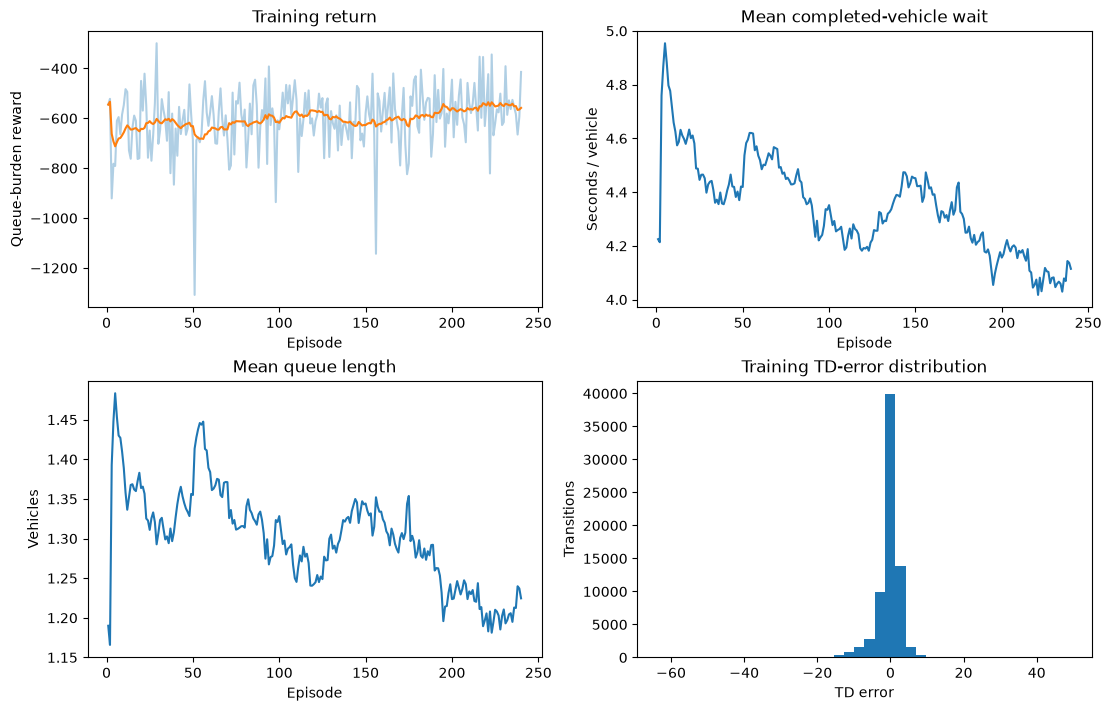

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
axes[0,0].plot(training_results.episode, training_results['return'], alpha=.35)
axes[0,0].plot(training_results.episode, training_results['return'].rolling(20, min_periods=1).mean())
axes[0,0].set(title='Training return', xlabel='Episode', ylabel='Queue-burden reward')
axes[0,1].plot(training_results.episode, training_results.mean_wait_seconds_per_completed_vehicle.rolling(20, min_periods=1).mean())
axes[0,1].set(title='Mean completed-vehicle wait', xlabel='Episode', ylabel='Seconds / vehicle')
axes[1,0].plot(training_results.episode, training_results.mean_queue_vehicles.rolling(20, min_periods=1).mean())
axes[1,0].set(title='Mean queue length', xlabel='Episode', ylabel='Vehicles')
axes[1,1].hist(agent.td_errors, bins=40)
axes[1,1].set(title='Training TD-error distribution', xlabel='TD error', ylabel='Transitions')
fig.savefig('results/training_diagnostics.png', dpi=150)
plt.show()

A moving average is a basic learning diagnostic, not a proof of convergence or global optimality. The TD error is a computational reward prediction error informed by dopamine research, not a biological measurement.

## E. Held-out testing and F. comparative evaluation
The evaluator does not update the Q-table. Each evaluation seed is run once per controller from a fresh environment with matching arrivals. Summary variability is sample standard deviation across scenarios; no significance test is applied.

In [5]:
q_before_evaluation = agent.q.copy()
evaluation_results, experiment_summary = evaluate(config, agent)
assert np.array_equal(q_before_evaluation, agent.q), 'Evaluation changed the trained policy'
display(evaluation_results.head())
display(pd.DataFrame({c: {m: v['mean'] for m, v in metrics.items()} for c, metrics in experiment_summary['results'].items()}))

,controller,seed,mean_wait_seconds_per_completed_vehicle,mean_queue_vehicles,completed_vehicles,episode_return,switches,waiting_vehicle_seconds
0,rl,90000,3.953488,1.151667,172,-519.0,49,691.0
1,fixed,90000,6.287356,1.825000,174,-921.0,23,1095.0
2,rl,90001,4.424084,1.408333,191,-654.0,49,845.0
3,fixed,90001,7.193717,2.290000,191,-1183.0,23,1374.0
4,rl,90002,3.260274,0.823333,146,-348.0,49,494.0


,fixed,rl
mean_wait_seconds_per_completed_vehicle,6.374874,4.081490
mean_queue_vehicles,1.919889,1.234667
completed_vehicles,176.866667,177.933333
episode_return,-975.066667,-562.866667
switches,23.000000,48.966667


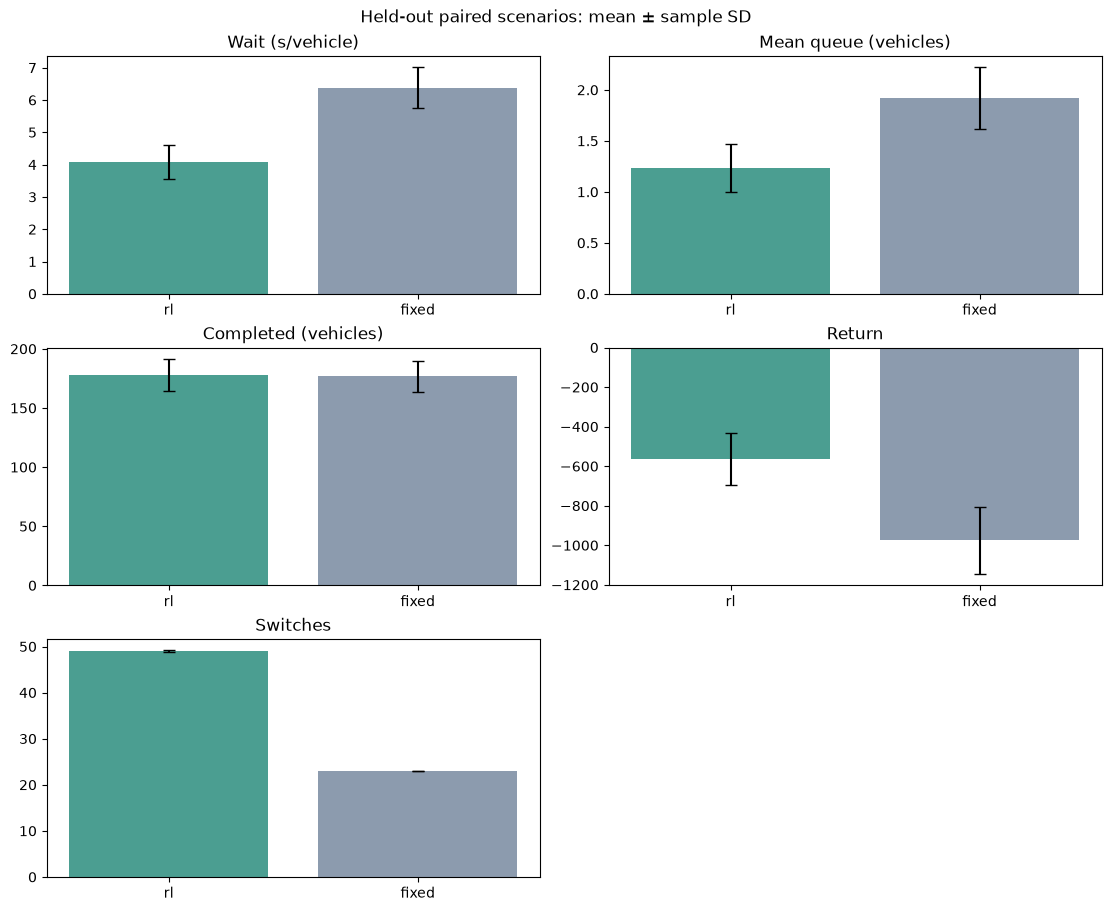

{
  "fixed": {
    "mean_wait_seconds_per_completed_vehicle": {
      "mean": 6.374874042045872,
      "std": 0.6364676089668875
    },
    "mean_queue_vehicles": {
      "mean": 1.9198888888888888,
      "std": 0.30120477541122015
    },
    "completed_vehicles": {
      "mean": 176.86666666666667,
      "std": 13.108915979626978
    },
    "episode_return": {
      "mean": -975.0666666666667,
      "std": 170.56881174537708
    },
    "switches": {
      "mean": 23.0,
      "std": 0.0
    }
  },
  "rl": {
    "mean_wait_seconds_per_completed_vehicle": {
      "mean": 4.081490013653957,
      "std": 0.5292264784635794
    },
    "mean_queue_vehicles": {
      "mean": 1.2346666666666666,
      "std": 0.2366138033886083
    },
    "completed_vehicles": {
      "mean": 177.93333333333334,
      "std": 13.567032387965025
    },
    "episode_return": {
      "mean": -562.8666666666667,
      "std": 130.77507231972723
    },
    "switches": {
      "mean": 48.96666666666667,
      "std": 0.

In [6]:
metrics = ['mean_wait_seconds_per_completed_vehicle', 'mean_queue_vehicles', 'completed_vehicles', 'episode_return', 'switches']
labels = ['Wait (s/vehicle)', 'Mean queue (vehicles)', 'Completed (vehicles)', 'Return', 'Switches']
fig, axes = plt.subplots(3, 2, figsize=(11, 9), constrained_layout=True)
for i, (metric, label) in enumerate(zip(metrics, labels)):
    ax = axes.flat[i]
    for controller, color in [('rl', '#4b9e91'), ('fixed', '#8c9bae')]:
        item = experiment_summary['results'][controller][metric]
        ax.bar(controller, item['mean'], yerr=item['std'], capsize=4, color=color)
    ax.set_title(label)
axes.flat[-1].axis('off')
fig.suptitle('Held-out paired scenarios: mean ± sample SD')
fig.savefig('results/evaluation_comparison.png', dpi=150)
plt.show()
print(json.dumps(experiment_summary['results'], indent=2))

## G. Optional ablation
Optional sensitivity work is deferred in the minimum version so the core paired evaluation remains easy to reproduce and audit.

## H. Policy export
The single browser artifact includes the learned Q-table, state/action contract, environment and training parameters, schema version, and SHA-256 integrity value. Export validates the artifact by reloading it and comparing its Q-values with the in-memory agent.

In [7]:
policy = export_policy(agent, config, 'artifacts/policy.json')
validated_policy = validate_policy('artifacts/policy.json', agent)
assert validated_policy['sha256'] == policy['sha256']
print({'schema_version': policy['schema_version'], 'state_count': policy['state_count'], 'sha256': policy['sha256'], 'validated': True})

{'schema_version': 1, 'state_count': 224, 'sha256': '7f28bd29de6c5a62ee6c5edfd7131391e5fb186e5c1ac227bffbebc50bb5f5e8', 'validated': True}


## Interpretation reminder
This experiment concerns a tabular controller in a simplified synthetic traffic world. Its measured performance cannot establish or validate a biological dopamine mechanism. See `docs/methodology.md` and `docs/experimental_report_template.md` for semantics, units, and reporting guidance.